# Résoudre l'équation de Burgers avec un PINN

Un PINN (*Physics-Informed Neural Network*) est un réseau de neurones qu'on entraîne non pas sur des
données, mais sur une équation. Ici le réseau prend en entrée une position $x$ et un temps $t$, et doit
renvoyer la vitesse $u(x, t)$ d'un fluide qui vérifie l'équation de Burgers visqueuse :

$$u_t + u\,u_x = \nu\,u_{xx}, \qquad x \in [-1, 1],\ t \in [0, 1],\ \nu = \frac{0{,}01}{\pi}$$

avec la condition initiale $u(x, 0) = -\sin(\pi x)$ et des bords fixes $u(-1, t) = u(1, t) = 0$.

Les trois termes ont un sens physique : $u_t$ est la variation dans le temps, $u\,u_x$ le transport
du fluide par lui-même (les zones rapides rattrapent les zones lentes) et $\nu\,u_{xx}$ la viscosité
qui lisse la solution. Au départ, la moitié gauche du fluide va vers la droite et la moitié droite
vers la gauche. Elles se rencontrent en $x = 0$ et, comme $\nu$ est très petit, la pente devient
presque verticale vers $t \approx 1/\pi \approx 0{,}32$ : un **choc** se forme. C'est ce qui rend le
problème intéressant (et difficile) pour un réseau de neurones.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float32)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Les contraintes et les points où on les impose

Le réseau doit respecter trois choses à la fois. Pour chacune, je choisis des points où je vais
vérifier si c'est le cas :

- **l'EDP** dans tout le domaine : 10 000 points de collocation tirés au hasard dans $[-1, 1] \times [0, 1]$.
  En ces points on veut que le résidu $f = u_t + u\,u_x - \nu\,u_{xx}$ soit nul ;
- **la condition initiale** : 200 points sur la ligne $t = 0$, où on veut $u = -\sin(\pi x)$ ;
- **les conditions aux bords** : 200 points sur $x = -1$ et 200 sur $x = 1$, où on veut $u = 0$.

Aucune valeur de la solution n'est donnée au réseau : seule l'équation lui sert de professeur.
Les points de collocation ont `requires_grad=True` parce qu'on va dériver $u$ par rapport à $x$ et $t$.

In [2]:
x_min, x_max = -1.0, 1.0
t_min, t_max = 0.0, 1.0
nu = 0.01 / np.pi

N_f, N_0, N_b = 10000, 200, 200

# points de collocation (EDP)
X_f = np.random.rand(N_f, 2)
X_f[:, 0] = X_f[:, 0] * (x_max - x_min) + x_min
X_f[:, 1] = X_f[:, 1] * (t_max - t_min) + t_min

# condition initiale
x0 = np.linspace(x_min, x_max, N_0)[:, None]
t0 = np.zeros_like(x0)
u0 = -np.sin(np.pi * x0)

# bords
tb = np.linspace(t_min, t_max, N_b)[:, None]
xb_left = np.ones_like(tb) * x_min
xb_right = np.ones_like(tb) * x_max

X_f = torch.tensor(X_f, dtype=torch.float32, requires_grad=True, device=device)
x0, t0, u0 = [torch.tensor(a, dtype=torch.float32, device=device) for a in (x0, t0, u0)]
tb, xb_left, xb_right = [torch.tensor(a, dtype=torch.float32, device=device) for a in (tb, xb_left, xb_right)]

## Le réseau

2 entrées $(x, t)$, 4 couches cachées de 50 neurones, 1 sortie $u$, soit 7 851 paramètres.

L'activation est **tanh** et ce n'est pas un détail. On va dériver le réseau deux fois par rapport à
$x$ pour obtenir $u_{xx}$. Avec ReLU, la dérivée seconde vaut 0 presque partout et le terme de
viscosité disparaîtrait de l'équation. tanh est lisse, on peut la dériver autant qu'on veut.

In [3]:
class PINN(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.activation = nn.Tanh()
        self.layers = nn.ModuleList([nn.Linear(layers[i], layers[i + 1]) for i in range(len(layers) - 1)])

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = self.activation(layer(x))
        return self.layers[-1](x)


model = PINN([2, 50, 50, 50, 50, 1]).to(device)
print(model)

PINN(
  (activation): Tanh()
  (layers): ModuleList(
    (0): Linear(in_features=2, out_features=50, bias=True)
    (1-3): 3 x Linear(in_features=50, out_features=50, bias=True)
    (4): Linear(in_features=50, out_features=1, bias=True)
  )
)


## La loss : la physique traduite en code

Pour évaluer le résidu il faut $u_t$, $u_x$ et $u_{xx}$. Pas de différences finies ici : PyTorch
calcule les dérivées **exactes** du réseau par différentiation automatique (`torch.autograd.grad`),
en appliquant la règle de dérivation en chaîne à travers toutes les couches.
`create_graph=True` garde ce calcul en mémoire pour pouvoir dériver une seconde fois ($u_{xx}$), puis
pour que l'optimiseur puisse dériver la loss par rapport aux poids.

La loss est la somme des trois erreurs quadratiques moyennes :

$$\mathcal{L}(\theta) = \underbrace{\frac{1}{N_f}\sum f(x_i, t_i)^2}_{\text{EDP}}
+ \underbrace{\frac{1}{N_0}\sum \big(u(x_i, 0) + \sin(\pi x_i)\big)^2}_{\text{condition initiale}}
+ \underbrace{\frac{1}{N_b}\sum u(\pm 1, t_i)^2}_{\text{bords}}$$

Si elle vaut 0, le réseau respecte exactement l'équation et toutes les conditions : c'est la solution.

In [4]:
def pde_residual(model, X):
    x = X[:, 0:1]
    t = X[:, 1:2]
    u = model(torch.cat([x, t], dim=1))
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    return u_t + u * u_x - nu * u_xx


def loss_func(model):
    loss_f = torch.mean(pde_residual(model, X_f) ** 2)                       # EDP
    loss_0 = torch.mean((model(torch.cat([x0, t0], dim=1)) - u0) ** 2)       # condition initiale
    u_left = model(torch.cat([xb_left, tb], dim=1))
    u_right = model(torch.cat([xb_right, tb], dim=1))
    loss_b = torch.mean(u_left ** 2) + torch.mean(u_right ** 2)              # bords
    return loss_f + loss_0 + loss_b

## Le choix de l'optimiseur : Adam ou L-BFGS ?

Entraîner le réseau, c'est trouver les poids qui rendent la loss la plus petite possible.
Deux optimiseurs sont possibles.

**Adam** est une descente de gradient améliorée. Il lisse la direction avec une moyenne des gradients
récents et adapte la taille du pas à chaque poids. Il démarre bien avec des poids aléatoires, mais
avec un pas fixe il finit par stagner, alors qu'un PINN a besoin d'une loss très basse pour être précis.

**L-BFGS** utilise en plus la courbure de la loss pour choisir ses pas : grands quand c'est plat,
petits quand ça tourne. La courbure exacte coûterait trop cher (62 millions de valeurs pour 7 851
poids), donc il l'estime à partir des 50 derniers pas (`history_size`). À chaque itération, une
recherche linéaire (`strong_wolfe`) teste plusieurs longueurs de pas et garde celle qui fait vraiment
baisser la loss. C'est pour ça qu'il faut lui donner une fonction `closure` qui recalcule la loss.

Ici la loss est toujours calculée sur les mêmes points (pas de mini-batch) : c'est le cas idéal pour
L-BFGS, et c'est lui que j'ai retenu. La phase Adam reste disponible ci-dessous en option.

In [5]:
UTILISER_ADAM = False     # True : quelques milliers d'itérations d'Adam avant L-BFGS

if UTILISER_ADAM:
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(5000):
        optimizer.zero_grad()
        loss = loss_func(model)
        loss.backward()
        optimizer.step()
        if (epoch + 1) % 1000 == 0:
            print(f"Adam epoch {epoch + 1}, Loss: {loss.item():.5e}")

In [6]:
optimizer_lbfgs = optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=5000,
    max_eval=5000,
    history_size=50,
    tolerance_grad=1e-5,
    tolerance_change=1e-9,
    line_search_fn="strong_wolfe",     # indispensable pour la stabilité
)
lbfgs_iter = 0


def closure():
    global lbfgs_iter
    optimizer_lbfgs.zero_grad()
    loss = loss_func(model)
    loss.backward()
    lbfgs_iter += 1
    if lbfgs_iter % 500 == 0:
        print(f"L-BFGS évaluation {lbfgs_iter}, loss : {loss.item():.5e}")
    return loss


optimizer_lbfgs.step(closure)
print(f"Loss finale : {loss_func(model).item():.5e}")

L-BFGS évaluation 500, loss : 3.01177e-03
L-BFGS évaluation 1000, loss : 9.98672e-04
L-BFGS évaluation 1500, loss : 4.71242e-04
L-BFGS évaluation 2000, loss : 3.02193e-04
L-BFGS évaluation 2500, loss : 1.92777e-04
L-BFGS évaluation 3000, loss : 1.26068e-04
L-BFGS évaluation 3500, loss : 9.08205e-05
L-BFGS évaluation 4000, loss : 6.98113e-05
L-BFGS évaluation 4500, loss : 5.53639e-05
L-BFGS évaluation 5000, loss : 4.00826e-05
Loss finale : 4.00826e-05


La loss descend régulièrement, jusqu'à $4 \times 10^{-5}$.

## La solution prédite

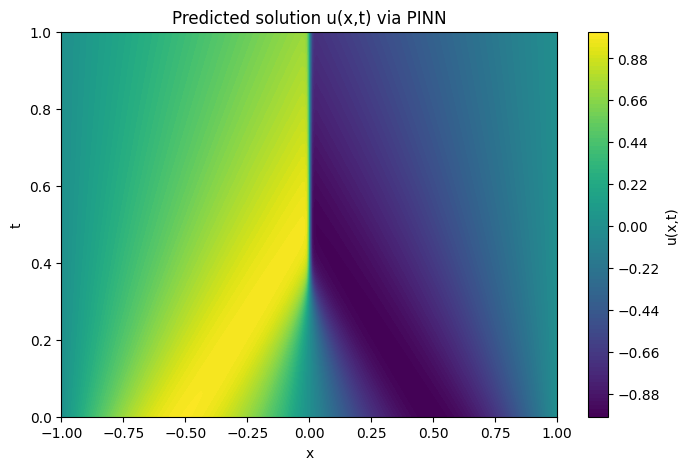

In [7]:
N_x, N_t = 256, 100
x = np.linspace(x_min, x_max, N_x)
t = np.linspace(t_min, t_max, N_t)
X, T = np.meshgrid(x, t)
XT = torch.tensor(np.hstack((X.flatten()[:, None], T.flatten()[:, None])), dtype=torch.float32, device=device)

model.eval()
with torch.no_grad():
    u_pred = model(XT).cpu().numpy().reshape(N_t, N_x)

plt.figure(figsize=(8, 5))
plt.contourf(X, T, u_pred, levels=100, cmap="viridis")
plt.colorbar(label="u(x,t)")
plt.xlabel("x")
plt.ylabel("t")
plt.title("Predicted solution u(x,t) via PINN")
plt.show()

On voit les deux zones (vitesse positive à gauche, négative à droite) qui se rejoignent, et la ligne
verticale du choc en $x = 0$ à partir de $t \approx 0{,}3$.

## Vérification avec la solution exacte

Burgers a un avantage rare : on connaît sa solution exacte. La transformation de Cole-Hopf
$u = -2\nu\,\varphi_x / \varphi$ la ramène à l'équation de la chaleur, ce qui donne

$$u(x,t) = \frac{\int \frac{x-y}{t}\, e^{-G(y)/2\nu}\,dy}{\int e^{-G(y)/2\nu}\,dy}, \qquad
G(y) = \frac{\cos(\pi y) - 1}{\pi} + \frac{(x-y)^2}{2t}$$

Je calcule ces intégrales avec la méthode des trapèzes. Comme $1/2\nu \approx 157$, les exponentielles
dépassent vite la capacité des flottants : je soustrais le maximum de l'exposant avant de prendre
l'exponentielle (il se simplifie entre le numérateur et le dénominateur).

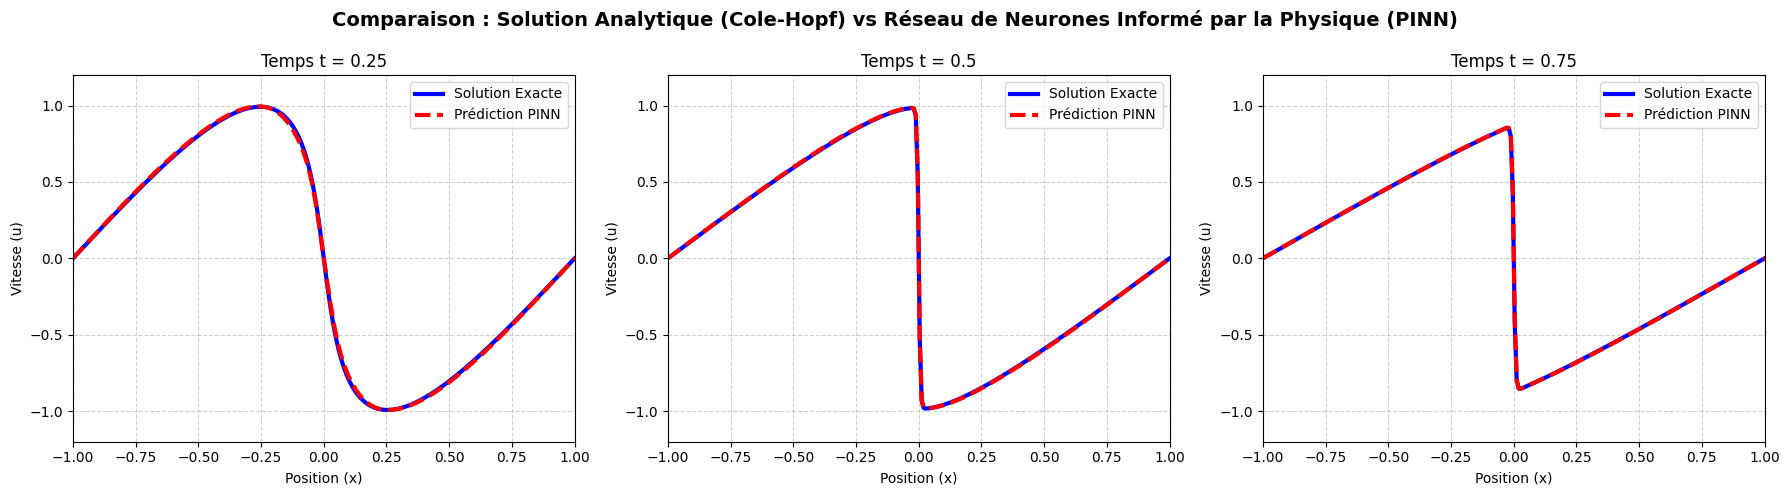

Erreur relative L2 : 4.512e-03


In [8]:
trapz = getattr(np, "trapezoid", None) or np.trapz


def exacte_burgers(x_array, t_val, nu):
    if t_val == 0:
        return -np.sin(np.pi * x_array)
    y = np.linspace(-3, 3, 2000)
    f_y = (np.cos(np.pi * y) - 1.0) / np.pi          # primitive de la condition initiale
    u_ex = np.zeros_like(x_array)
    for i, xi in enumerate(x_array):
        exponent = -(f_y + (xi - y) ** 2 / (2 * t_val)) / (2 * nu)
        w = np.exp(exponent - np.max(exponent))      # évite l'overflow
        u_ex[i] = trapz(((xi - y) / t_val) * w, y) / trapz(w, y)
    return u_ex


times_to_plot = [0.25, 0.50, 0.75]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Comparaison : Solution Analytique (Cole-Hopf) vs Réseau de Neurones Informé par la Physique (PINN)",
             fontsize=14, fontweight="bold")
for ax, t_val in zip(axes, times_to_plot):
    t_idx = int(t_val * (N_t - 1))
    ax.plot(x, exacte_burgers(x, t_val, nu), "b-", linewidth=3, label="Solution Exacte")
    ax.plot(x, u_pred[t_idx, :], "r--", linewidth=3, label="Prédiction PINN")
    ax.set_title(f"Temps t = {t_val}")
    ax.set_xlabel("Position (x)")
    ax.set_ylabel("Vitesse (u)")
    ax.set_xlim([-1, 1])
    ax.set_ylim([-1.2, 1.2])
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

u_exact_all = np.array([exacte_burgers(x, t_val, nu) for t_val in t])
error_l2 = np.linalg.norm(u_exact_all - u_pred) / np.linalg.norm(u_exact_all)
print(f"Erreur relative L2 : {error_l2:.3e}")

Les courbes se superposent, y compris dans le choc, et l'erreur relative sur toute la grille est
inférieure à 0,5 %.

## Animation du choc

In [9]:
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_xlim(x_min, x_max)
ax.set_ylim(-1.2, 1.2)
ax.set_xlabel("x")
ax.set_ylabel("u(x,t)")
ax.grid(True, linestyle="--", alpha=0.6)
line, = ax.plot([], [], lw=3, color="crimson")
time_text = ax.text(0.65, 0.9, "", transform=ax.transAxes, fontsize=12)


def update(frame):
    line.set_data(x, u_pred[frame, :])
    time_text.set_text(f"Temps t = {t[frame]:.2f}")
    return line, time_text


anim = FuncAnimation(fig, update, frames=N_t, blit=True, interval=50)
anim.save("burgers_choc.gif", writer="pillow")
plt.close(fig)

![choc](https://raw.githubusercontent.com/nour395/pinn-equation-burgers/main/figures/resultat_profil.gif)

Référence : M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks*,
Journal of Computational Physics 378 (2019).